# Hyderabad Roads — Spatial Analysis and Clustering

**Dataset:** `data/processed/infrastructure/roads_processed.csv`  
**Purpose:** Explore road classes, recorded attributes, road-segment lengths and spatial concentration. Prepare approximate road-density features for later integration with infrastructure points.

> **Important limitations:** Each row contains a representative latitude/longitude and a segment length, not full road geometry. Nearby counts and summed lengths are therefore spatial approximations, not exact road-network coverage, connectivity, route distance or travel time. Missing OSM attributes remain unknown; they are not treated as negative values.

## 1. Imports and configuration

This notebook uses the actual eight-column CSV structure inspected in PowerShell. The DBSCAN comparison uses a reproducible spatial sample to keep computation practical for 93,000+ records. KMeans is evaluated on a sample and then fitted to all records.

In [9]:
from pathlib import Path
import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.neighbors import BallTree

# =====================================
# PROJECT DIRECTORY
# =====================================

PROJECT_DIR = Path(
    r"C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics"
)

if not PROJECT_DIR.exists():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_DIR}")

os.chdir(PROJECT_DIR)

# =====================================
# CONFIGURATION
# =====================================

RANDOM_STATE = 42

DATA_PATH = PROJECT_DIR / "data/processed/infrastructure/roads_processed.csv"
OUTPUT_DIR = PROJECT_DIR / "data/processed/infrastructure/roads_experiments"
MODEL_DIR = PROJECT_DIR / "models/infrastructure"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

warnings.filterwarnings("ignore")

# =====================================
# VERIFY
# =====================================

print("Project directory:", Path.cwd())
print("Input exists:", DATA_PATH.exists())
print("Output directory:", OUTPUT_DIR)
print("Model directory:", MODEL_DIR)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"CSV not found: {DATA_PATH}")

Project directory: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics
Input exists: True
Output directory: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\roads_experiments
Model directory: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\infrastructure


## 2. Load the data

Expected columns: `osm_id`, `road_name`, `road_type`, `maxspeed`, `oneway`, `latitude`, `longitude`, `length_km`.

In [10]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
expected_columns = {
    "osm_id", "road_name", "road_type", "maxspeed",
    "oneway", "latitude", "longitude", "length_km"
}
missing_columns = expected_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")

print("Shape:", df.shape)
display(df.head())

Shape: (93437, 8)


,osm_id,road_name,road_type,maxspeed,oneway,latitude,longitude,length_km
0,way/22831055,NaN,trunk,60.0,yes,17.401277,78.549785,1.7416
1,way/22839614,Brigadier Sayeed Road,tertiary,NaN,no,17.467287,78.482014,0.3261
2,way/22839658,NaN,trunk,50.0,NaN,17.384764,78.498192,0.7703
3,way/22839666,NaN,secondary,NaN,NaN,17.458340,78.513146,0.5193
4,way/22839714,Sainikpuri Road,secondary,60.0,yes,17.480535,78.534132,0.5061


## 3. Data audit and preprocessing

We retain missing road names, speed limits and one-way values because these are optional OpenStreetMap attributes. We remove only rows with invalid coordinates or invalid/non-positive segment lengths, and exact duplicate OSM IDs are reported before any removal.

In [11]:
roads = df.copy()
for col in ["latitude", "longitude", "maxspeed", "length_km"]:
    roads[col] = pd.to_numeric(roads[col], errors="coerce")

roads["road_type"] = roads["road_type"].astype("string").str.strip().str.lower()
roads["road_name"] = roads["road_name"].astype("string").str.strip()
roads["oneway"] = roads["oneway"].astype("string").str.strip().str.lower()

duplicate_osm_ids = int(roads["osm_id"].duplicated().sum())
valid_coord = (
    roads["latitude"].between(-90, 90) &
    roads["longitude"].between(-180, 180)
)
valid_length = roads["length_km"].gt(0) & roads["length_km"].notna()
valid_type = roads["road_type"].notna() & roads["road_type"].ne("")

invalid_mask = ~(valid_coord & valid_length & valid_type)
invalid_rows = roads.loc[invalid_mask].copy()
roads = roads.loc[~invalid_mask].copy()
roads = roads.drop_duplicates(subset=["osm_id"], keep="first").reset_index(drop=True)

audit = {
    "source_records": int(len(df)),
    "records_after_cleaning": int(len(roads)),
    "invalid_records_removed": int(len(invalid_rows)),
    "duplicate_osm_ids_in_source": duplicate_osm_ids,
    "missing_road_name": int(roads["road_name"].isna().sum()),
    "missing_maxspeed": int(roads["maxspeed"].isna().sum()),
    "missing_oneway": int(roads["oneway"].isna().sum()),
    "missing_coordinates_after_cleaning": int(roads[["latitude", "longitude"]].isna().any(axis=1).sum()),
    "missing_or_nonpositive_lengths_after_cleaning": int((roads["length_km"].isna() | roads["length_km"].le(0)).sum())
}
display(pd.DataFrame([audit]).T.rename(columns={0: "value"}))
invalid_rows.to_csv(OUTPUT_DIR / "roads_invalid_records.csv", index=False)

,value
source_records,93437
records_after_cleaning,93437
invalid_records_removed,0
duplicate_osm_ids_in_source,0
missing_road_name,85798
missing_maxspeed,90037
missing_oneway,86222
missing_coordinates_after_cleaning,0
missing_or_nonpositive_lengths_after_cleaning,0


## 4. Exploratory data analysis — road classes

The count plot shows how many OSM road-segment records belong to each road class. Counts are not equivalent to total road kilometres, so the next analysis also compares summed segment length.

,road_type,segment_count,total_length_km,mean_segment_length_km,median_segment_length_km
0,residential,85620,10360.6252,0.121007,0.08380
1,tertiary,3138,919.6032,0.293054,0.15590
2,secondary,1780,515.1710,0.289422,0.10420
3,primary,1468,426.8185,0.290748,0.09485
4,trunk,836,264.1045,0.315914,0.12365
5,unclassified,464,99.0506,0.213471,0.09555
6,motorway,131,45.6713,0.348636,0.20930


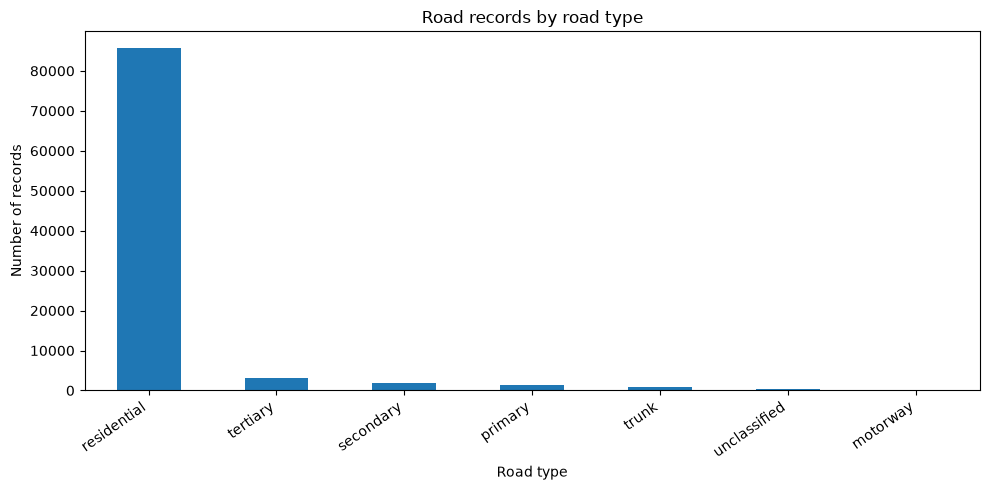

In [12]:
road_type_counts = roads["road_type"].value_counts().rename_axis("road_type").reset_index(name="segment_count")
road_type_summary = (
    roads.groupby("road_type", dropna=False)
    .agg(segment_count=("osm_id", "size"), total_length_km=("length_km", "sum"),
         mean_segment_length_km=("length_km", "mean"), median_segment_length_km=("length_km", "median"))
    .sort_values("segment_count", ascending=False)
    .reset_index()
)
display(road_type_summary)

ax = road_type_counts.plot(kind="bar", x="road_type", y="segment_count", legend=False, figsize=(10, 5))
ax.set_title("Road records by road type")
ax.set_xlabel("Road type")
ax.set_ylabel("Number of records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

road_type_summary.to_csv(OUTPUT_DIR / "road_type_summary.csv", index=False)

## 5. Segment length analysis

A few long segments can pull the mean above the median. We inspect the distribution and compare length by road type. These are lengths recorded per OSM way/segment in the processed dataset.

,length_km
count,93437.000000
mean,0.135182
std,0.182821
min,0.000500
25%,0.044900
50%,0.085000
75%,0.158600
max,8.205400


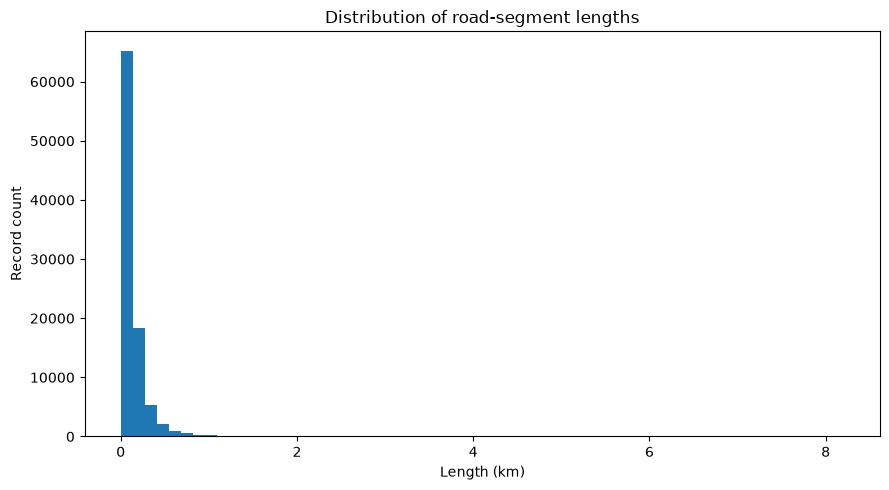

,segment_count,total_km,mean_km,median_km
road_type,,,,
residential,85620,10360.6252,0.121007,0.08380
tertiary,3138,919.6032,0.293054,0.15590
secondary,1780,515.1710,0.289422,0.10420
primary,1468,426.8185,0.290748,0.09485
trunk,836,264.1045,0.315914,0.12365
unclassified,464,99.0506,0.213471,0.09555
motorway,131,45.6713,0.348636,0.20930


In [13]:
display(roads["length_km"].describe().to_frame("length_km"))
plt.figure(figsize=(9, 5))
plt.hist(roads["length_km"], bins=60)
plt.title("Distribution of road-segment lengths")
plt.xlabel("Length (km)")
plt.ylabel("Record count")
plt.tight_layout()
plt.show()

length_by_type = roads.groupby("road_type")["length_km"].agg(
    segment_count="count", total_km="sum", mean_km="mean", median_km="median"
).sort_values("total_km", ascending=False)
display(length_by_type)
length_by_type.to_csv(OUTPUT_DIR / "road_length_by_type.csv")

## 6. Speed-limit analysis

Only records with a recorded numeric `maxspeed` are included. Missing speed limits are unknown, not zero. Values are summarized and checked for unusual values; they are not filled in.

In [14]:
known_speed = roads.loc[roads["maxspeed"].notna() & roads["maxspeed"].gt(0)].copy()
print("Records with known speed limit:", len(known_speed))
print("Records with missing speed limit:", int(roads["maxspeed"].isna().sum()))
display(known_speed["maxspeed"].describe().to_frame("maxspeed_kmh"))

speed_by_type = known_speed.groupby("road_type")["maxspeed"].agg(
    records="count", mean_kmh="mean", median_kmh="median", min_kmh="min", max_kmh="max"
).sort_values("records", ascending=False)
display(speed_by_type)
speed_by_type.to_csv(OUTPUT_DIR / "speed_summary_by_road_type.csv")

Records with known speed limit: 3400
Records with missing speed limit: 90037


,maxspeed_kmh
count,3400.000000
mean,54.944118
std,15.144099
min,10.000000
25%,60.000000
50%,60.000000
75%,60.000000
max,120.000000


,records,mean_kmh,median_kmh,min_kmh,max_kmh
road_type,,,,,
primary,1175,59.106383,60.0,20.0,60.0
secondary,837,56.511350,60.0,20.0,60.0
trunk,773,59.547219,60.0,30.0,60.0
residential,367,23.405995,20.0,10.0,60.0
tertiary,121,36.859504,30.0,20.0,60.0
motorway,116,92.068966,80.0,40.0,120.0
unclassified,11,27.272727,30.0,20.0,40.0


## 7. One-way attribute analysis

The chart separates known `yes`, known `no`, and missing values. A missing value is not assumed to mean a two-way road.

,oneway_status,records
0,unknown,86222
1,yes,6830
2,no,385


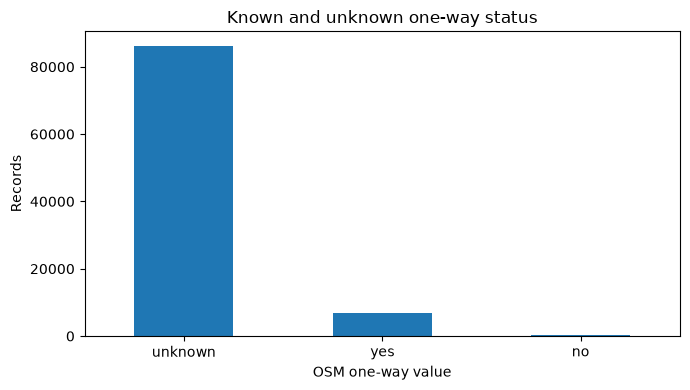

In [15]:
oneway_counts = roads["oneway"].fillna("unknown").value_counts().rename_axis("oneway_status").reset_index(name="records")
display(oneway_counts)
ax = oneway_counts.plot(kind="bar", x="oneway_status", y="records", legend=False, figsize=(7, 4))
ax.set_title("Known and unknown one-way status")
ax.set_xlabel("OSM one-way value")
ax.set_ylabel("Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
oneway_counts.to_csv(OUTPUT_DIR / "oneway_status_summary.csv", index=False)

## 8. Geographic coverage and coordinate preparation

For local spatial comparisons, latitude/longitude are converted to an approximate local kilometre coordinate system using an equirectangular projection centred on the dataset. This is suitable for exploratory clustering over this compact Hyderabad-area extent; it is not a replacement for a road-network projection or routing engine.

Centre latitude: 17.423493899880633
Centre longitude: 78.46726965741578
Latitude range: (np.float64(17.277726598101264), np.float64(17.557367581818184))
Longitude range: (np.float64(78.23883746666667), np.float64(78.625484792))


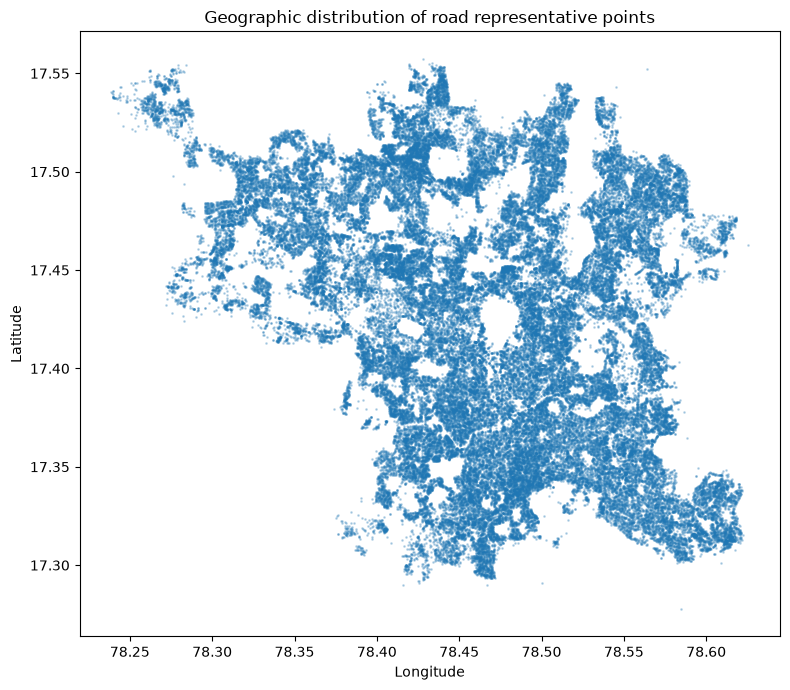

In [16]:
center_lat = float(roads["latitude"].mean())
center_lon = float(roads["longitude"].mean())
EARTH_RADIUS_KM = 6371.0088

roads["x_km"] = np.radians(roads["longitude"] - center_lon) * EARTH_RADIUS_KM * np.cos(np.radians(center_lat))
roads["y_km"] = np.radians(roads["latitude"] - center_lat) * EARTH_RADIUS_KM

print("Centre latitude:", center_lat)
print("Centre longitude:", center_lon)
print("Latitude range:", (roads["latitude"].min(), roads["latitude"].max()))
print("Longitude range:", (roads["longitude"].min(), roads["longitude"].max()))

plt.figure(figsize=(8, 7))
plt.scatter(roads["longitude"], roads["latitude"], s=1, alpha=0.25)
plt.title("Geographic distribution of road representative points")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

## 9. Spatial density features

For each road representative point, count other road representative points and sum their recorded segment lengths within 0.5 km and 1 km. The query includes the point's own record, so the counts and length sums include the current segment. Results are approximations because the input does not contain full road geometries.

In [17]:
coords_rad = np.radians(roads[["latitude", "longitude"]].to_numpy())
tree = BallTree(coords_rad, metric="haversine")
length_values = roads["length_km"].to_numpy()
density_features = {}

for radius_km in [0.5, 1.0]:
    radius_rad = radius_km / EARTH_RADIUS_KM
    counts = np.empty(len(roads), dtype=np.int32)
    length_sums = np.empty(len(roads), dtype=np.float64)
    chunk_size = 2000

    for start in range(0, len(roads), chunk_size):
        end = min(start + chunk_size, len(roads))
        neighborhoods = tree.query_radius(coords_rad[start:end], r=radius_rad, return_distance=False)
        for offset, indices in enumerate(neighborhoods):
            row_idx = start + offset
            counts[row_idx] = len(indices)
            length_sums[row_idx] = length_values[indices].sum()

    suffix = str(radius_km).replace(".", "_")
    density_features[f"nearby_road_record_count_{suffix}km"] = counts
    density_features[f"nearby_road_length_sum_{suffix}km"] = length_sums

for name, values in density_features.items():
    roads[name] = values

display(roads[[
    "osm_id", "road_type", "length_km",
    "nearby_road_record_count_0_5km", "nearby_road_length_sum_0_5km",
    "nearby_road_record_count_1_0km", "nearby_road_length_sum_1_0km"
]].head())

,osm_id,road_type,length_km,nearby_road_record_count_0_5km,nearby_road_length_sum_0_5km,nearby_road_record_count_1_0km,nearby_road_length_sum_1_0km
0,way/22831055,trunk,1.7416,15,5.0891,184,35.5941
1,way/22839614,tertiary,0.3261,183,18.9379,505,62.5606
2,way/22839658,trunk,0.7703,154,15.8228,676,75.3769
3,way/22839666,secondary,0.5193,54,9.3532,262,37.0100
4,way/22839714,secondary,0.5061,164,19.8962,572,83.5110


## 10. KMeans spatial clustering — model selection

KMeans groups representative road locations geographically. It does not predict road quality, congestion, accessibility or risk. We compare `k=2` through `k=8` using a reproducible sample and silhouette score, then fit the selected configuration to all cleaned records.

,k,silhouette,inertia
0,2,0.405768,633350.746308
1,3,0.410817,406306.108377
2,4,0.419884,290117.922585
3,5,0.403113,227103.925623
4,6,0.397458,190453.021294
5,7,0.404399,158057.026225
6,8,0.397297,139265.093246


Selected k: 4


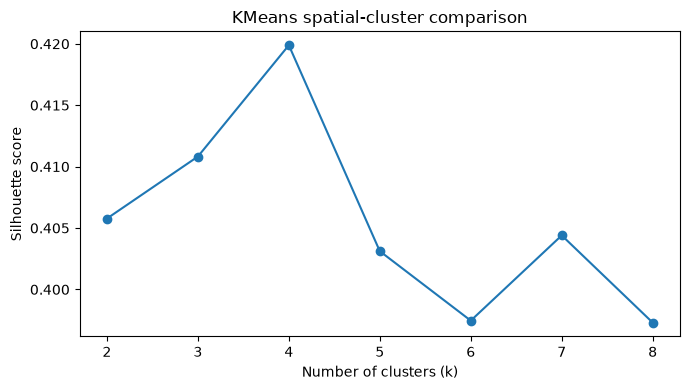

In [18]:
xy = roads[["x_km", "y_km"]].to_numpy()
rng = np.random.default_rng(RANDOM_STATE)
sample_size = min(10000, len(roads))
sample_idx = rng.choice(len(roads), size=sample_size, replace=False)
xy_sample = xy[sample_idx]

kmeans_results = []
for k in range(2, 9):
    candidate = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = candidate.fit_predict(xy_sample)
    score = silhouette_score(xy_sample, labels, sample_size=min(5000, len(xy_sample)), random_state=RANDOM_STATE)
    kmeans_results.append({"k": k, "silhouette": score, "inertia": candidate.inertia_})

kmeans_comparison = pd.DataFrame(kmeans_results)
display(kmeans_comparison)
best_k = int(kmeans_comparison.loc[kmeans_comparison["silhouette"].idxmax(), "k"])
print("Selected k:", best_k)

plt.figure(figsize=(7, 4))
plt.plot(kmeans_comparison["k"], kmeans_comparison["silhouette"], marker="o")
plt.title("KMeans spatial-cluster comparison")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.xticks(range(2, 9))
plt.tight_layout()
plt.show()

final_kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
roads["kmeans_cluster"] = final_kmeans.fit_predict(xy)
kmeans_comparison.to_csv(OUTPUT_DIR / "roads_kmeans_comparison.csv", index=False)

## 11. DBSCAN spatial clustering — parameter comparison

DBSCAN can identify dense spatial groups and mark sparse points as noise (`-1`). Because the dataset has over 93,000 records, this comparison is run on a fixed sample of up to 15,000 records. Scores are calculated only when at least two non-noise clusters exist and the sample is large enough. Compare both silhouette and the fraction of records assigned to clusters.

In [19]:
dbscan_sample_size = min(15000, len(roads))
db_idx = rng.choice(len(roads), size=dbscan_sample_size, replace=False)
db_coords_rad = coords_rad[db_idx]
eps_values_km = [0.25, 0.5, 0.75, 1.0]
min_samples_values = [5, 10]
dbscan_results = []

for eps_km in eps_values_km:
    for min_samples in min_samples_values:
        model = DBSCAN(eps=eps_km / EARTH_RADIUS_KM, min_samples=min_samples, metric="haversine", algorithm="ball_tree")
        labels = model.fit_predict(db_coords_rad)
        non_noise = labels != -1
        cluster_labels = set(labels[non_noise])
        n_clusters = len(cluster_labels)
        n_clustered = int(non_noise.sum())
        score = np.nan
        if n_clusters >= 2 and n_clustered > n_clusters:
            positions = np.where(non_noise)[0]
            score = silhouette_score(
                db_coords_rad[positions], labels[positions],
                metric="haversine", sample_size=min(3000, len(positions)),
                random_state=RANDOM_STATE
            ) * EARTH_RADIUS_KM
        dbscan_results.append({
            "eps_km": eps_km, "min_samples": min_samples,
            "clusters_excluding_noise": n_clusters,
            "clustered_records": n_clustered,
            "noise_records": int((~non_noise).sum()),
            "noise_percent": round((~non_noise).mean() * 100, 2),
            "silhouette_non_noise_km_scaled": score
        })

dbscan_comparison = pd.DataFrame(dbscan_results)
display(dbscan_comparison)
dbscan_comparison.to_csv(OUTPUT_DIR / "roads_dbscan_comparison.csv", index=False)

,eps_km,min_samples,clusters_excluding_noise,clustered_records,noise_records,noise_percent,silhouette_non_noise_km_scaled
0,0.25,5,211,13960,1040,6.93,-1995.669691
1,0.25,10,301,8745,6255,41.70,2003.913389
2,0.50,5,15,14929,71,0.47,-2412.445477
3,0.50,10,20,14822,178,1.19,-2967.363353
4,0.75,5,5,14991,9,0.06,241.772873
5,0.75,10,5,14964,36,0.24,-554.457021
6,1.00,5,1,15000,0,0.00,NaN
7,1.00,10,1,14994,6,0.04,NaN


## 12. Save spatial outputs and clustering artifacts

KMeans supports assigning future coordinates to its learned spatial clusters, so we save the fitted estimator and projection metadata together. DBSCAN is retained as an exploratory density-clustering comparison; standard DBSCAN does not provide a native `predict` method for unseen points, so we save its comparison results rather than presenting it as a deployable predictor.

In [20]:
roads.to_csv(OUTPUT_DIR / "roads_clean_with_spatial_features.csv", index=False)
road_type_summary.to_csv(OUTPUT_DIR / "road_type_summary.csv", index=False)
length_by_type.to_csv(OUTPUT_DIR / "road_length_by_type.csv")
oneway_counts.to_csv(OUTPUT_DIR / "oneway_status_summary.csv", index=False)

kmeans_artifact = {
    "model": final_kmeans,
    "center_latitude": center_lat,
    "center_longitude": center_lon,
    "earth_radius_km": EARTH_RADIUS_KM,
    "selected_k": best_k,
    "feature_columns": ["x_km", "y_km"],
    "interpretation": "Exploratory geographic clusters of road representative points; not road-risk labels."
}
joblib.dump(kmeans_artifact, MODEL_DIR / "roads_spatial_kmeans.joblib")

summary = {
    **audit,
    "clean_records": int(len(roads)),
    "road_type_count": int(roads["road_type"].nunique()),
    "selected_kmeans_k": best_k,
    "dbscan_comparison_sample_size": int(dbscan_sample_size),
    "density_radii_km": [0.5, 1.0],
    "supervised_model_trained": False,
    "road_geometry_available": False,
    "interpretation": "Spatial clustering and representative-point density analysis only; no validated road-risk labels or route-network analysis.",
    "outputs_directory": str(OUTPUT_DIR.resolve())
}
with open(OUTPUT_DIR / "roads_analysis_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)

print(json.dumps(summary, indent=4))
print("\nSaved KMeans artifact:", (MODEL_DIR / "roads_spatial_kmeans.joblib").resolve())
print("Saved outputs:", OUTPUT_DIR.resolve())

{
    "source_records": 93437,
    "records_after_cleaning": 93437,
    "invalid_records_removed": 0,
    "duplicate_osm_ids_in_source": 0,
    "missing_road_name": 85798,
    "missing_maxspeed": 90037,
    "missing_oneway": 86222,
    "missing_coordinates_after_cleaning": 0,
    "missing_or_nonpositive_lengths_after_cleaning": 0,
    "clean_records": 93437,
    "road_type_count": 7,
    "selected_kmeans_k": 4,
    "dbscan_comparison_sample_size": 15000,
    "density_radii_km": [
        0.5,
        1.0
    ],
    "supervised_model_trained": false,
    "road_geometry_available": false,
    "interpretation": "Spatial clustering and representative-point density analysis only; no validated road-risk labels or route-network analysis.",
    "outputs_directory": "C:\\Users\\sanaf\\OneDrive\\Desktop\\urban-risk-analytics\\data\\processed\\infrastructure\\roads_experiments"
}

Saved KMeans artifact: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\infrastructure\roads_spatial_kmean

## 13. Final interpretation and limitations

1. The dataset is dominated by residential road records; report both record counts and summed segment lengths.
2. Speed-limit analysis applies only to the subset with recorded speed values.
3. Missing `oneway` values remain unknown.
4. KMeans and DBSCAN reveal spatial groupings, not road-condition or risk classes.
5. Nearby-road record counts and summed lengths use representative points and are approximate.
6. The CSV does not contain road geometry, intersections, turn restrictions or a routable graph. Do not calculate actual shortest paths or emergency travel times from this file alone.
7. These road features can be joined spatially with infrastructure points in a later integration stage, with the same representative-point limitation clearly documented.

In [24]:
from pathlib import Path
import pandas as pd

INTEGRATED_DIR = (
    Path(r"C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics")
    / "data/processed/infrastructure/integrated_infrastructure_experiments"
)

INTEGRATED_FILE = INTEGRATED_DIR / "integrated_infrastructure_road_grid_1km.csv"

print("File exists:", INTEGRATED_FILE.exists())
print("File path:", INTEGRATED_FILE)

if not INTEGRATED_FILE.exists():
    raise FileNotFoundError(f"Integrated CSV not found: {INTEGRATED_FILE}")

integrated = pd.read_csv(INTEGRATED_FILE)

print("\nDataset shape:", integrated.shape)
print("\nColumn names:")
print(integrated.columns.tolist())

print("\nDescriptive statistics:")
display(integrated.describe().round(2).T)

print("\nCells flagged for further investigation:")
display(
    integrated[integrated["investigation_flag"]]
    .sort_values(
        ["total_infrastructure_records", "road_representative_point_count"]
    )
    .head(15)
)

File exists: True
File path: C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experiments\integrated_infrastructure_road_grid_1km.csv

Dataset shape: (791, 26)

Column names:
['grid_id', 'grid_x', 'grid_y', 'infra_building_count', 'infra_fire_station_count', 'infra_hospital_count', 'road_representative_point_count', 'road_segment_length_sum_km', 'mean_recorded_segment_length_km', 'unique_road_types', 'roadtype_motorway_count', 'roadtype_primary_count', 'roadtype_residential_count', 'roadtype_secondary_count', 'roadtype_tertiary_count', 'roadtype_trunk_count', 'roadtype_unclassified_count', 'cell_center_x_km', 'cell_center_y_km', 'cell_center_longitude', 'cell_center_latitude', 'total_infrastructure_records', 'total_road_type_records', 'low_infrastructure_records', 'low_road_point_count', 'investigation_flag']

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
grid_x,791.0,22.46,9.73,0.00,16.00,23.00,30.00,41.00
grid_y,791.0,18.15,7.79,0.00,12.00,19.00,24.00,32.00
infra_building_count,791.0,1.27,4.69,0.00,0.00,0.00,1.00,85.00
infra_fire_station_count,791.0,0.01,0.09,0.00,0.00,0.00,0.00,1.00
infra_hospital_count,791.0,1.36,2.55,0.00,0.00,0.00,2.00,26.00
road_representative_point_count,791.0,118.13,87.06,0.00,34.00,114.00,189.00,415.00
road_segment_length_sum_km,791.0,15.97,10.10,0.00,6.83,16.31,24.54,44.32
mean_recorded_segment_length_km,791.0,0.23,0.50,0.00,0.12,0.14,0.17,8.21
unique_road_types,791.0,2.53,1.23,0.00,2.00,2.00,3.00,6.00
roadtype_motorway_count,791.0,0.17,1.04,0.00,0.00,0.00,0.00,14.00



Cells flagged for further investigation:


,grid_id,grid_x,grid_y,infra_building_count,infra_fire_station_count,infra_hospital_count,road_representative_point_count,road_segment_length_sum_km,mean_recorded_segment_length_km,unique_road_types,...,roadtype_unclassified_count,cell_center_x_km,cell_center_y_km,cell_center_longitude,cell_center_latitude,total_infrastructure_records,total_road_type_records,low_infrastructure_records,low_road_point_count,investigation_flag
64,14_14,14,14,0.0,0.0,0.0,1,0.0708,0.0708,1.0,...,0.0,14.5,14.5,78.375235,17.391088,0.0,1.0,True,True,True
133,17_11,17,11,0.0,0.0,0.0,1,1.0855,1.0855,1.0,...,0.0,17.5,11.5,78.403455,17.363957,0.0,1.0,True,True,True
179,18_3,18,3,0.0,0.0,0.0,1,1.8214,1.8214,1.0,...,0.0,18.5,3.5,78.412862,17.291607,0.0,1.0,True,True,True
353,24_29,24,29,0.0,0.0,0.0,1,0.0977,0.0977,1.0,...,0.0,24.5,29.5,78.469302,17.526744,0.0,1.0,True,True,True
432,27_3,27,3,0.0,0.0,0.0,1,4.8717,4.8717,1.0,...,0.0,27.5,3.5,78.497522,17.291607,0.0,1.0,True,True,True
433,27_30,27,30,0.0,0.0,0.0,1,1.6876,1.6876,1.0,...,0.0,27.5,30.5,78.497522,17.535788,0.0,1.0,True,True,True
462,28_6,28,6,0.0,0.0,0.0,1,1.0231,1.0231,1.0,...,0.0,28.5,6.5,78.506929,17.318738,0.0,1.0,True,True,True
492,2_28,2,28,0.0,0.0,0.0,1,0.0134,0.0134,1.0,...,0.0,2.5,28.5,78.262354,17.517700,0.0,1.0,True,True,True
538,31_6,31,6,0.0,0.0,0.0,1,0.0326,0.0326,1.0,...,0.0,31.5,6.5,78.535149,17.318738,0.0,1.0,True,True,True
563,32_31,32,31,0.0,0.0,0.0,1,1.1798,1.1798,1.0,...,0.0,32.5,31.5,78.544556,17.544831,0.0,1.0,True,True,True


In [25]:
# Check which datasets are represented in each cell

integrated["has_infrastructure"] = (
    integrated["total_infrastructure_records"] > 0
)

integrated["has_roads"] = (
    integrated["road_representative_point_count"] > 0
)

both = (
    integrated["has_infrastructure"]
    & integrated["has_roads"]
)

infra_only = (
    integrated["has_infrastructure"]
    & ~integrated["has_roads"]
)

roads_only = (
    ~integrated["has_infrastructure"]
    & integrated["has_roads"]
)

neither = (
    ~integrated["has_infrastructure"]
    & ~integrated["has_roads"]
)

print("Total cells:", len(integrated))
print("Both infrastructure and roads:", both.sum())
print("Infrastructure only:", infra_only.sum())
print("Roads only:", roads_only.sum())
print("Neither:", neither.sum())

print("\nInvestigation flag distribution:")
print(integrated["investigation_flag"].value_counts())

Total cells: 791
Both infrastructure and roads: 388
Infrastructure only: 28
Roads only: 375
Neither: 0

Investigation flag distribution:
investigation_flag
False    658
True     133
Name: count, dtype: int64


In [26]:
# Inspect cells selected for further investigation

flagged_cells = integrated[
    integrated["investigation_flag"] == True
].copy()

print("Number of flagged cells:", len(flagged_cells))

display(
    flagged_cells[
        [
            "grid_id",
            "infra_building_count",
            "infra_hospital_count",
            "infra_fire_station_count",
            "road_representative_point_count",
            "road_segment_length_sum_km",
            "low_infrastructure_records",
            "low_road_point_count",
            "investigation_flag"
        ]
    ].head(20)
)

Number of flagged cells: 133


,grid_id,infra_building_count,infra_hospital_count,infra_fire_station_count,road_representative_point_count,road_segment_length_sum_km,low_infrastructure_records,low_road_point_count,investigation_flag
0,0_29,0.0,0.0,0.0,2,1.8762,True,True,True
1,0_30,0.0,0.0,0.0,26,4.3406,True,True,True
2,0_31,0.0,0.0,0.0,5,2.6975,True,True,True
4,10_16,0.0,0.0,0.0,4,0.2473,True,True,True
8,10_20,0.0,0.0,0.0,27,4.4665,True,True,True
19,11_16,0.0,0.0,0.0,5,1.4613,True,True,True
21,11_18,0.0,0.0,0.0,29,2.4740,True,True,True
24,11_21,0.0,0.0,0.0,28,4.6376,True,True,True
30,11_27,0.0,0.0,0.0,23,5.5243,True,True,True
33,12_18,0.0,0.0,0.0,5,2.5695,True,True,True


In [27]:
# Understand why cells received an investigation flag

print("Flagged cells by infrastructure availability:")
print(
    flagged_cells["total_infrastructure_records"]
    .value_counts()
    .sort_index()
)

print("\nRoad representative point statistics for flagged cells:")
print(
    flagged_cells["road_representative_point_count"]
    .describe()
)

print("\nFlagged cells by data availability:")
print(
    flagged_cells["has_infrastructure"].value_counts()
)

print("\nFlagged cells with both datasets:")
print(
    (
        flagged_cells["has_infrastructure"]
        & flagged_cells["has_roads"]
    ).sum()
)

Flagged cells by infrastructure availability:
total_infrastructure_records
0.0    133
Name: count, dtype: int64

Road representative point statistics for flagged cells:
count    133.000000
mean      11.676692
std       10.427636
min        1.000000
25%        3.000000
50%        7.000000
75%       20.000000
max       34.000000
Name: road_representative_point_count, dtype: float64

Flagged cells by data availability:
has_infrastructure
False    133
Name: count, dtype: int64

Flagged cells with both datasets:
0


In [28]:
import numpy as np

# 1. Calculate infrastructure threshold using only cells
#    that actually contain infrastructure records.
positive_infra = integrated.loc[
    integrated["total_infrastructure_records"] > 0,
    "total_infrastructure_records"
]

infra_threshold = positive_infra.quantile(0.25)

# 2. Calculate road threshold across all occupied grid cells.
road_threshold = integrated[
    "road_representative_point_count"
].quantile(0.25)

# 3. Create separate diagnostic conditions.
integrated["no_infrastructure_records"] = (
    integrated["total_infrastructure_records"] == 0
)

integrated["low_infrastructure_present"] = (
    (integrated["total_infrastructure_records"] > 0)
    & (integrated["total_infrastructure_records"] <= infra_threshold)
)

integrated["low_road_representation"] = (
    integrated["road_representative_point_count"] <= road_threshold
)

# 4. Assign mutually exclusive diagnostic categories.
conditions = [
    integrated["no_infrastructure_records"],

    integrated["low_infrastructure_present"]
    & integrated["low_road_representation"],

    integrated["low_infrastructure_present"],

    integrated["low_road_representation"]
]

choices = [
    "No mapped infrastructure",
    "Both relatively low",
    "Low infrastructure only",
    "Low road representation only"
]

integrated["diagnostic_category"] = np.select(
    conditions,
    choices,
    default="Neither relatively low"
)

# 5. Display results.
print("Infrastructure threshold:", infra_threshold)
print("Road representation threshold:", road_threshold)

print("\nDiagnostic category distribution:")
print(
    integrated["diagnostic_category"]
    .value_counts()
)

print("\nCategory percentages:")
print(
    integrated["diagnostic_category"]
    .value_counts(normalize=True).mul(100).round(2)
)

Infrastructure threshold: 1.0
Road representation threshold: 34.0

Diagnostic category distribution:
diagnostic_category
No mapped infrastructure        375
Neither relatively low          262
Low infrastructure only          88
Both relatively low              37
Low road representation only     29
Name: count, dtype: int64

Category percentages:
diagnostic_category
No mapped infrastructure        47.41
Neither relatively low          33.12
Low infrastructure only         11.13
Both relatively low              4.68
Low road representation only     3.67
Name: proportion, dtype: float64


In [29]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

# 1. Select clustering features.
clustering_features = [
    "infra_building_count",
    "infra_hospital_count",
    "infra_fire_station_count",
    "road_representative_point_count",
    "road_segment_length_sum_km",
    "unique_road_types"
]

X = integrated[clustering_features].copy()

# 2. Check missing values.
print("Missing values:")
print(X.isnull().sum())

# 3. Apply log1p transformation.
# This reduces the influence of highly skewed counts.
X_log = np.log1p(X)

# 4. Scale the transformed features.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

# 5. Convert back to DataFrame for easier inspection.
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=clustering_features,
    index=integrated.index
)

print("\nOriginal feature shape:", X.shape)
print("Transformed feature shape:", X_log.shape)
print("Scaled feature shape:", X_scaled.shape)

print("\nScaled feature summary:")
display(X_scaled_df.describe().round(3))

print("\nFeature preparation completed.")

Missing values:
infra_building_count               0
infra_hospital_count               0
infra_fire_station_count           0
road_representative_point_count    0
road_segment_length_sum_km         0
unique_road_types                  0
dtype: int64

Original feature shape: (791, 6)
Transformed feature shape: (791, 6)
Scaled feature shape: (791, 6)

Scaled feature summary:


,infra_building_count,infra_hospital_count,infra_fire_station_count,road_representative_point_count,road_segment_length_sum_km,unique_road_types
count,791.000,791.000,791.000,791.000,791.000,791.000
mean,-0.000,-0.000,-0.000,-0.000,-0.000,0.000
std,1.001,1.001,1.001,1.001,1.001,1.001
min,-0.564,-0.744,-0.094,-2.793,-2.667,-2.983
25%,-0.564,-0.744,-0.094,-0.412,-0.492,-0.227
50%,-0.564,-0.744,-0.094,0.384,0.348,-0.227
75%,0.424,0.787,-0.094,0.720,0.759,0.495
max,5.784,3.848,10.583,1.245,1.365,1.899



Feature preparation completed.


In [30]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

results = []

# Compare two feature sets:
# A. All six features
# B. Five features without the sparse fire-station count

feature_sets = {
    "All six features": X_scaled,
    "Without fire station": StandardScaler().fit_transform(
        np.log1p(
            integrated[
                [
                    "infra_building_count",
                    "infra_hospital_count",
                    "road_representative_point_count",
                    "road_segment_length_sum_km",
                    "unique_road_types"
                ]
            ]
        )
    )
}

for feature_name, feature_data in feature_sets.items():

    for k in range(2, 9):

        # KMeans
        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=20
        )

        kmeans_labels = kmeans.fit_predict(feature_data)

        results.append({
            "features": feature_name,
            "algorithm": "KMeans",
            "k": k,
            "silhouette": silhouette_score(
                feature_data, kmeans_labels
            ),
            "davies_bouldin": davies_bouldin_score(
                feature_data, kmeans_labels
            ),
            "calinski_harabasz": calinski_harabasz_score(
                feature_data, kmeans_labels
            )
        })

        # Agglomerative Clustering
        agg = AgglomerativeClustering(
            n_clusters=k,
            linkage="ward"
        )

        agg_labels = agg.fit_predict(feature_data)

        results.append({
            "features": feature_name,
            "algorithm": "Agglomerative",
            "k": k,
            "silhouette": silhouette_score(
                feature_data, agg_labels
            ),
            "davies_bouldin": davies_bouldin_score(
                feature_data, agg_labels
            ),
            "calinski_harabasz": calinski_harabasz_score(
                feature_data, agg_labels
            )
        })

results_df = pd.DataFrame(results)

print("Clustering comparison completed.")

display(
    results_df.sort_values(
        ["features", "silhouette"],
        ascending=[True, False]
    ).round(4)
)

Clustering comparison completed.


,features,algorithm,k,silhouette,davies_bouldin,calinski_harabasz
3,All six features,Agglomerative,3,0.4361,0.6609,348.6586
1,All six features,Agglomerative,2,0.4128,0.8352,342.3251
2,All six features,KMeans,3,0.3831,0.7922,380.7947
4,All six features,KMeans,4,0.3719,0.8534,491.1653
0,All six features,KMeans,2,0.3677,1.0648,381.2182
5,All six features,Agglomerative,4,0.3356,0.9006,454.2550
6,All six features,KMeans,5,0.3259,0.9163,479.0268
10,All six features,KMeans,7,0.3156,0.9501,480.1025
12,All six features,KMeans,8,0.3137,0.9565,474.7393
8,All six features,KMeans,6,0.3065,0.9935,485.9373


INTEGRATED DATA AUDIT
Dataset shape: (791, 26)
Missing values: 0

EXPERIMENT A: ALL GRID CELLS

Infrastructure-present cells: 416

Partition clustering results: (56, 9)
DBSCAN results: (60, 10)

BEST PARTITION CONFIGURATIONS


,dataset,feature_set,algorithm,k,silhouette,davies_bouldin,calinski_harabasz,clusters,noise_percentage
0,all_791_cells,all_six,Agglomerative,3,0.4361,0.6609,348.6586,3,0
1,all_791_cells,without_fire_station,Agglomerative,2,0.4320,0.8104,449.1963,2,0
2,infrastructure_present_416_cells,all_six,Agglomerative,3,0.6134,0.4412,208.6705,3,0
3,infrastructure_present_416_cells,without_fire_station,Agglomerative,2,0.6103,0.3538,278.5574,2,0


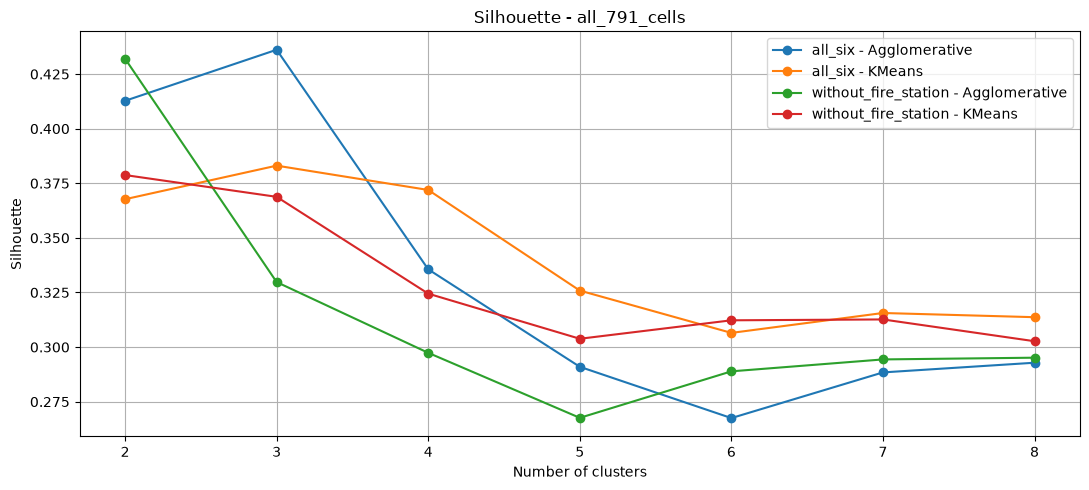

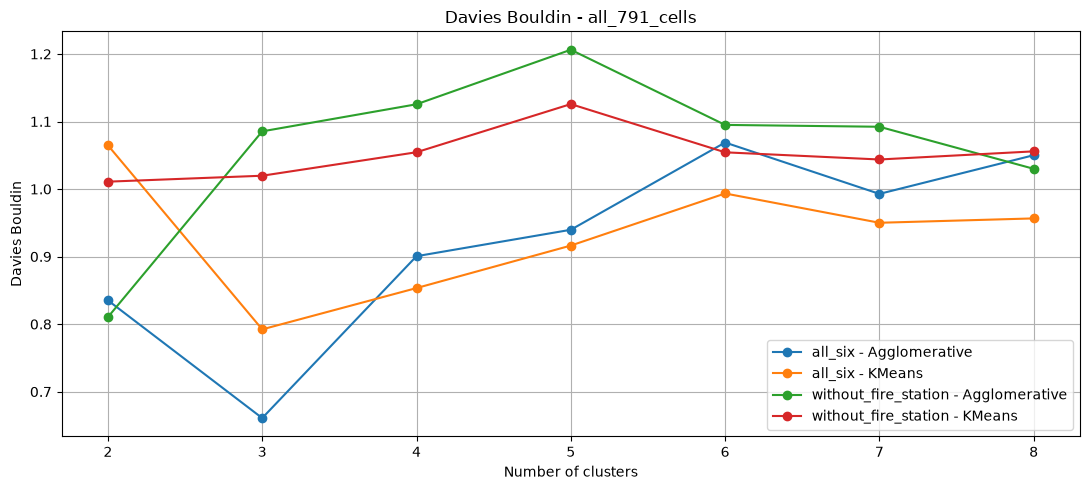

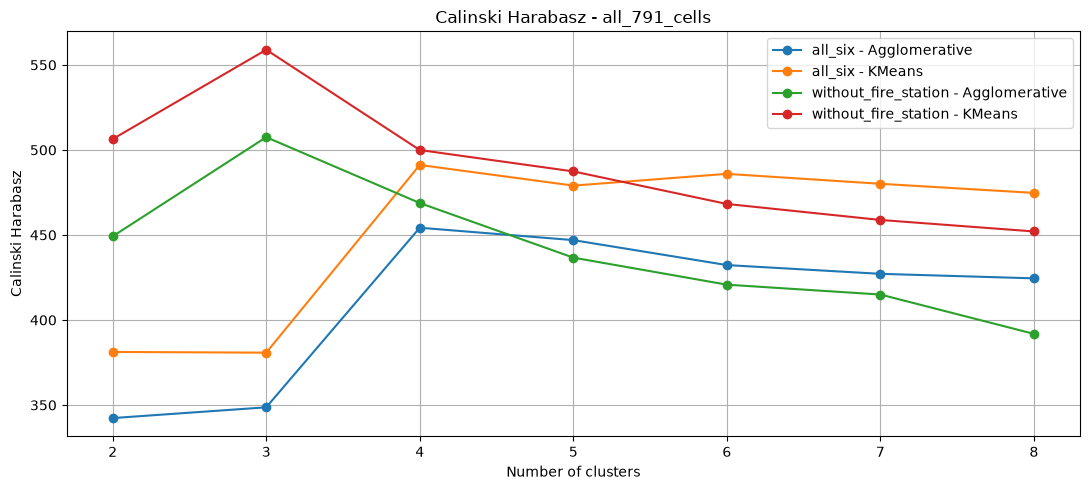

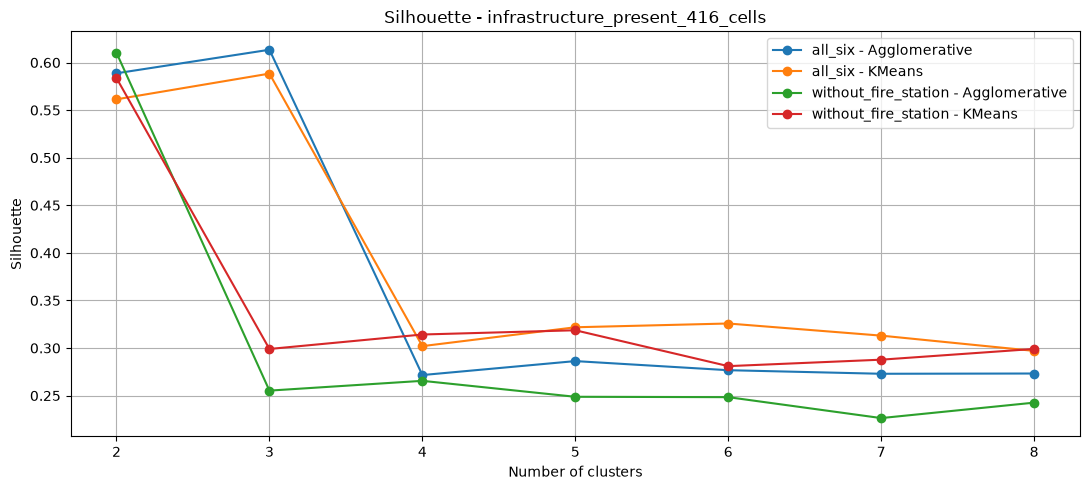

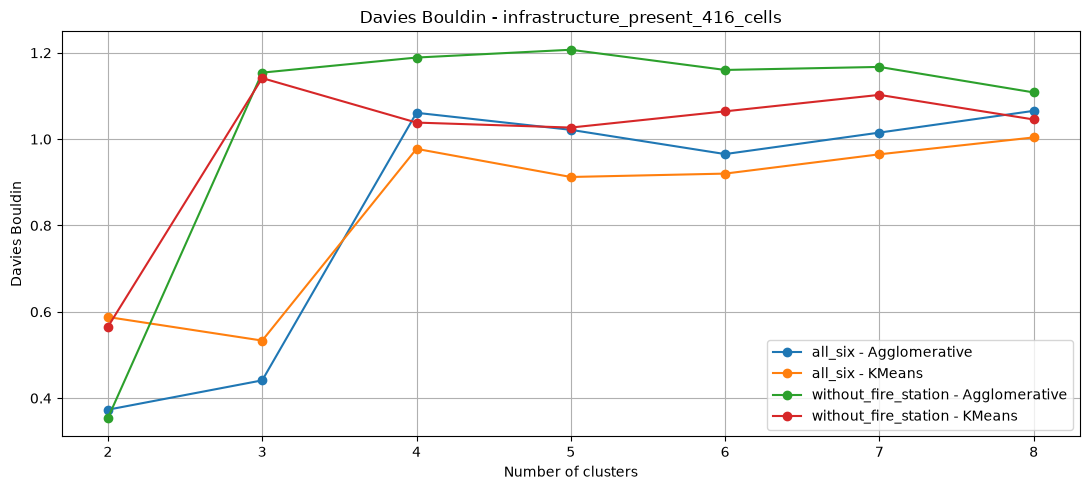

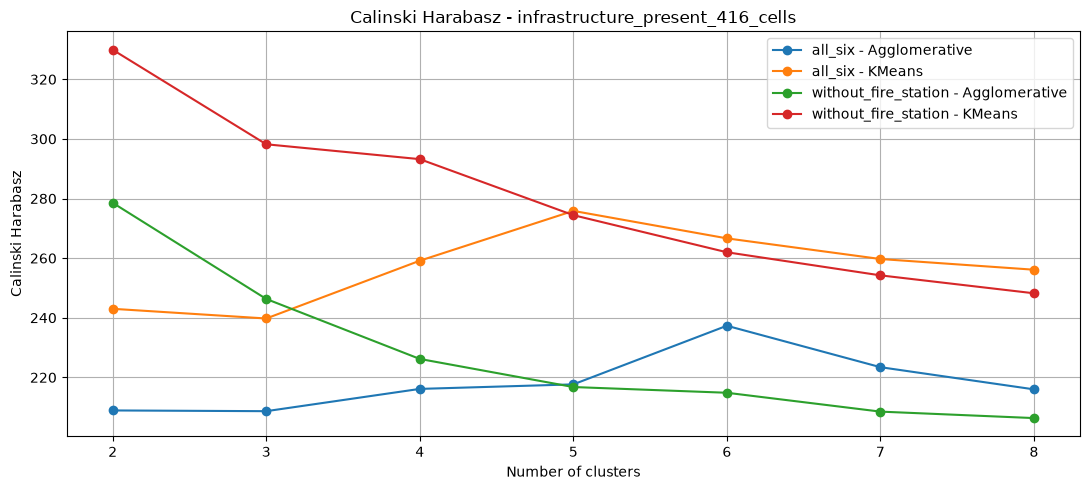


INTEGRATED CLUSTERING EXPERIMENT COMPLETED
All grid cells: 791
Infrastructure-present cells: 416
Partition configurations evaluated: 56
DBSCAN configurations evaluated: 60

Output directory:
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\data\processed\infrastructure\integrated_infrastructure_experiments\clustering_experiments

Model directory:
C:\Users\sanaf\OneDrive\Desktop\urban-risk-analytics\models\infrastructure

Important:
Cluster IDs are exploratory groups, not validated risk categories.


In [31]:
# ============================================================
# INTEGRATED INFRASTRUCTURE CLUSTERING EXPERIMENT
# ============================================================

import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import (
    KMeans,
    AgglomerativeClustering,
    DBSCAN
)
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# ------------------------------------------------------------
# 1. OUTPUT DIRECTORY
# ------------------------------------------------------------

PROJECT_ROOT = os.getcwd()

INTEGRATED_DIR = os.path.join(
    PROJECT_ROOT,
    "data",
    "processed",
    "infrastructure",
    "integrated_infrastructure_experiments"
)

CLUSTER_DIR = os.path.join(
    INTEGRATED_DIR,
    "clustering_experiments"
)

MODEL_DIR = os.path.join(
    PROJECT_ROOT,
    "models",
    "infrastructure"
)

os.makedirs(CLUSTER_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD INTEGRATED DATA
# ------------------------------------------------------------

INPUT_FILE = os.path.join(
    INTEGRATED_DIR,
    "integrated_infrastructure_road_grid_1km.csv"
)

integrated = pd.read_csv(INPUT_FILE)

print("=" * 65)
print("INTEGRATED DATA AUDIT")
print("=" * 65)

print("Dataset shape:", integrated.shape)
print("Missing values:", integrated.isnull().sum().sum())

# ------------------------------------------------------------
# 3. DEFINE FEATURES
# ------------------------------------------------------------

features_all = [
    "infra_building_count",
    "infra_hospital_count",
    "infra_fire_station_count",
    "road_representative_point_count",
    "road_segment_length_sum_km",
    "unique_road_types"
]

features_without_fire = [
    "infra_building_count",
    "infra_hospital_count",
    "road_representative_point_count",
    "road_segment_length_sum_km",
    "unique_road_types"
]

# ------------------------------------------------------------
# 4. DATA PREPARATION FUNCTION
# ------------------------------------------------------------

def prepare_features(data, feature_columns):

    X = data[feature_columns].copy()

    if X.isnull().sum().sum() > 0:
        raise ValueError("Missing values found in clustering features.")

    if (X < 0).any().any():
        raise ValueError("Negative values found in count/length features.")

    X_log = np.log1p(X)

    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(X_log)

    return X_scaled, scaler, X_log


# ------------------------------------------------------------
# 5. CLUSTER EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_clustering(X, labels):

    unique_labels = np.unique(labels)

    # Exclude DBSCAN noise from internal metrics.
    if -1 in unique_labels:
        mask = labels != -1
        X_eval = X[mask]
        labels_eval = labels[mask]
    else:
        X_eval = X
        labels_eval = labels

    n_clusters = len(np.unique(labels_eval))

    if n_clusters < 2 or len(X_eval) <= n_clusters:
        return None

    return {
        "silhouette": silhouette_score(X_eval, labels_eval),
        "davies_bouldin": davies_bouldin_score(
            X_eval, labels_eval
        ),
        "calinski_harabasz": calinski_harabasz_score(
            X_eval, labels_eval
        ),
        "clusters": n_clusters,
        "noise_percentage": (
            np.mean(labels == -1) * 100
            if -1 in unique_labels else 0
        )
    }


# ------------------------------------------------------------
# 6. KMEANS AND AGGLOMERATIVE COMPARISON
# ------------------------------------------------------------

def compare_partition_algorithms(data, dataset_name):

    result_rows = []
    fitted_models = {}
    prepared_data = {}

    feature_sets = {
        "all_six": features_all,
        "without_fire_station": features_without_fire
    }

    for feature_name, columns in feature_sets.items():

        X, scaler, X_log = prepare_features(data, columns)

        prepared_data[feature_name] = {
            "X": X,
            "scaler": scaler,
            "columns": columns
        }

        for k in range(2, 9):

            algorithms = {
                "KMeans": KMeans(
                    n_clusters=k,
                    random_state=RANDOM_STATE,
                    n_init=20
                ),
                "Agglomerative": AgglomerativeClustering(
                    n_clusters=k,
                    linkage="ward"
                )
            }

            for algorithm_name, model in algorithms.items():

                labels = model.fit_predict(X)

                metrics = evaluate_clustering(X, labels)

                if metrics is None:
                    continue

                result_rows.append({
                    "dataset": dataset_name,
                    "feature_set": feature_name,
                    "algorithm": algorithm_name,
                    "k": k,
                    **metrics
                })

                fitted_models[
                    (feature_name, algorithm_name, k)
                ] = {
                    "model": model,
                    "labels": labels,
                    "scaler": scaler,
                    "columns": columns
                }

    return (
        pd.DataFrame(result_rows),
        fitted_models,
        prepared_data
    )


# ------------------------------------------------------------
# 7. DBSCAN COMPARISON
# ------------------------------------------------------------

def compare_dbscan(data, dataset_name):

    rows = []
    models = {}

    feature_sets = {
        "all_six": features_all,
        "without_fire_station": features_without_fire
    }

    for feature_name, columns in feature_sets.items():

        X, scaler, _ = prepare_features(data, columns)

        for eps in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]:

            for min_samples in [5, 10, 15]:

                model = DBSCAN(
                    eps=eps,
                    min_samples=min_samples
                )

                labels = model.fit_predict(X)

                metrics = evaluate_clustering(X, labels)

                if metrics is None:
                    continue

                rows.append({
                    "dataset": dataset_name,
                    "feature_set": feature_name,
                    "algorithm": "DBSCAN",
                    "eps": eps,
                    "min_samples": min_samples,
                    **metrics
                })

                models[
                    (feature_name, eps, min_samples)
                ] = {
                    "model": model,
                    "labels": labels,
                    "scaler": scaler,
                    "columns": columns
                }

    return pd.DataFrame(rows), models


# ------------------------------------------------------------
# 8. RUN EXPERIMENT ON ALL GRID CELLS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EXPERIMENT A: ALL GRID CELLS")
print("=" * 65)

all_results, all_models, all_prepared = (
    compare_partition_algorithms(
        integrated,
        "all_791_cells"
    )
)

all_dbscan_results, all_dbscan_models = (
    compare_dbscan(
        integrated,
        "all_791_cells"
    )
)

# ------------------------------------------------------------
# 9. RUN EXPERIMENT ON INFRASTRUCTURE-PRESENT CELLS
# ------------------------------------------------------------

infra_present = integrated[
    integrated["total_infrastructure_records"] > 0
].copy()

print("\nInfrastructure-present cells:", len(infra_present))

infra_results, infra_models, infra_prepared = (
    compare_partition_algorithms(
        infra_present,
        "infrastructure_present_416_cells"
    )
)

infra_dbscan_results, infra_dbscan_models = (
    compare_dbscan(
        infra_present,
        "infrastructure_present_416_cells"
    )
)

# ------------------------------------------------------------
# 10. COMBINE AND SAVE RESULTS
# ------------------------------------------------------------

partition_results = pd.concat(
    [all_results, infra_results],
    ignore_index=True
)

dbscan_results = pd.concat(
    [all_dbscan_results, infra_dbscan_results],
    ignore_index=True
)

partition_results.to_csv(
    os.path.join(CLUSTER_DIR, "partition_clustering_results.csv"),
    index=False
)

dbscan_results.to_csv(
    os.path.join(CLUSTER_DIR, "dbscan_clustering_results.csv"),
    index=False
)

print("\nPartition clustering results:", partition_results.shape)
print("DBSCAN results:", dbscan_results.shape)

# ------------------------------------------------------------
# 11. SELECT BEST PARTITION CONFIGURATIONS
# ------------------------------------------------------------

# Silhouette is used to shortlist candidates, not as the
# sole criterion for deciding the final interpretation.

best_partition = (
    partition_results
    .sort_values("silhouette", ascending=False)
    .groupby(["dataset", "feature_set"], as_index=False)
    .first()
)

print("\nBEST PARTITION CONFIGURATIONS")
display(best_partition.round(4))

# ------------------------------------------------------------
# 12. CLUSTER PROFILE FUNCTION
# ------------------------------------------------------------

profile_features = features_all

def make_cluster_profile(data, labels):

    temp = data[profile_features].copy()
    temp["cluster"] = labels

    profile = temp.groupby("cluster").agg(
        ["count", "mean", "median"]
    )

    return profile


# ------------------------------------------------------------
# 13. SAVE CLUSTER ASSIGNMENTS AND PROFILES
# ------------------------------------------------------------

def save_partition_outputs(
    data,
    fitted_models,
    dataset_name
):

    for key, result in fitted_models.items():

        feature_name, algorithm_name, k = key

        labels = result["labels"]

        output = data.copy()
        output["cluster"] = labels

        filename = (
            f"{dataset_name}_{feature_name}_"
            f"{algorithm_name.lower()}_k{k}.csv"
        )

        output.to_csv(
            os.path.join(CLUSTER_DIR, filename),
            index=False
        )

        profile = make_cluster_profile(
            data,
            labels
        )

        profile.to_csv(
            os.path.join(
                CLUSTER_DIR,
                filename.replace(".csv", "_profile.csv")
            )
        )

        # Save KMeans models only.
        # Agglomerative has no standard predict method.
        if algorithm_name == "KMeans":

            joblib.dump(
                {
                    "model": result["model"],
                    "scaler": result["scaler"],
                    "feature_columns": result["columns"],
                    "cluster_count": k,
                    "dataset": dataset_name,
                    "feature_set": feature_name
                },
                os.path.join(
                    MODEL_DIR,
                    f"{dataset_name}_{feature_name}_kmeans_k{k}.joblib"
                )
            )


save_partition_outputs(
    integrated,
    all_models,
    "all_791_cells"
)

save_partition_outputs(
    infra_present,
    infra_models,
    "infrastructure_present_416_cells"
)

# ------------------------------------------------------------
# 14. SAVE DBSCAN ASSIGNMENTS
# ------------------------------------------------------------

def save_dbscan_outputs(data, models, dataset_name):

    for key, result in models.items():

        feature_name, eps, min_samples = key

        output = data.copy()
        output["dbscan_cluster"] = result["labels"]

        filename = (
            f"{dataset_name}_{feature_name}_"
            f"dbscan_eps{eps}_min{min_samples}.csv"
        )

        output.to_csv(
            os.path.join(CLUSTER_DIR, filename),
            index=False
        )


save_dbscan_outputs(
    integrated,
    all_dbscan_models,
    "all_791_cells"
)

save_dbscan_outputs(
    infra_present,
    infra_dbscan_models,
    "infrastructure_present_416_cells"
)

# ------------------------------------------------------------
# 15. VISUALIZE METRIC COMPARISONS
# ------------------------------------------------------------

for dataset_name in partition_results["dataset"].unique():

    subset = partition_results[
        partition_results["dataset"] == dataset_name
    ]

    for metric in [
        "silhouette",
        "davies_bouldin",
        "calinski_harabasz"
    ]:

        plt.figure(figsize=(11, 5))

        for (feature_set, algorithm), group in subset.groupby(
            ["feature_set", "algorithm"]
        ):

            group = group.sort_values("k")

            plt.plot(
                group["k"],
                group[metric],
                marker="o",
                label=f"{feature_set} - {algorithm}"
            )

        plt.title(
            f"{metric.replace('_', ' ').title()} - {dataset_name}"
        )

        plt.xlabel("Number of clusters")
        plt.ylabel(metric.replace("_", " ").title())
        plt.xticks(range(2, 9))
        plt.legend()
        plt.grid(True)
        plt.tight_layout()

        plt.savefig(
            os.path.join(
                CLUSTER_DIR,
                f"{dataset_name}_{metric}.png"
            )
        )

        plt.show()
        plt.close()

# ------------------------------------------------------------
# 16. SAVE EXPERIMENT SUMMARY
# ------------------------------------------------------------

summary = {
    "total_grid_cells": int(len(integrated)),
    "infrastructure_present_cells": int(len(infra_present)),
    "cells_without_mapped_infrastructure": int(
        len(integrated) - len(infra_present)
    ),
    "features_all": features_all,
    "features_without_fire_station": features_without_fire,
    "partition_algorithms": [
        "KMeans",
        "Agglomerative"
    ],
    "dbscan_eps_values": [0.5, 0.75, 1.0, 1.25, 1.5, 2.0],
    "dbscan_min_samples_values": [5, 10, 15],
    "cluster_range": [2, 8],
    "random_state": RANDOM_STATE,
    "supervised_model_trained": False,
    "interpretation": (
        "Exploratory unsupervised clustering of mapped "
        "infrastructure and road-record density. "
        "Clusters are not validated urban-risk labels."
    )
}

with open(
    os.path.join(CLUSTER_DIR, "clustering_summary.json"),
    "w"
) as f:

    json.dump(summary, f, indent=4)

# ------------------------------------------------------------
# 17. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("INTEGRATED CLUSTERING EXPERIMENT COMPLETED")
print("=" * 65)

print("All grid cells:", len(integrated))
print("Infrastructure-present cells:", len(infra_present))

print("Partition configurations evaluated:", len(partition_results))
print("DBSCAN configurations evaluated:", len(dbscan_results))

print("\nOutput directory:")
print(CLUSTER_DIR)

print("\nModel directory:")
print(MODEL_DIR)

print("\nImportant:")
print(
    "Cluster IDs are exploratory groups, not validated risk categories."
)

In [32]:
# ============================================================
# INSPECT PROMISING CLUSTER CONFIGURATIONS
# ============================================================

import os
import pandas as pd

CLUSTER_DIR = os.path.join(
    os.getcwd(),
    "data",
    "processed",
    "infrastructure",
    "integrated_infrastructure_experiments",
    "clustering_experiments"
)

# Features used to describe cluster profiles.
profile_columns = [
    "infra_building_count",
    "infra_hospital_count",
    "infra_fire_station_count",
    "road_representative_point_count",
    "road_segment_length_sum_km",
    "unique_road_types"
]

# Four promising configurations.
candidates = {
    "All cells - 3 clusters - six features":
        "all_791_cells_all_six_agglomerative_k3.csv",

    "All cells - 2 clusters - without fire stations":
        "all_791_cells_without_fire_station_agglomerative_k2.csv",

    "Infrastructure-present - 3 clusters - six features":
        "infrastructure_present_416_cells_all_six_agglomerative_k3.csv",

    "Infrastructure-present - 2 clusters - without fire stations":
        "infrastructure_present_416_cells_without_fire_station_agglomerative_k2.csv"
}

# ------------------------------------------------------------
# 1. CLUSTER SIZES AND PROFILES
# ------------------------------------------------------------

for description, filename in candidates.items():

    filepath = os.path.join(CLUSTER_DIR, filename)

    data = pd.read_csv(filepath)

    print("\n" + "=" * 70)
    print(description)
    print("=" * 70)

    print("\nCluster sizes:")
    print(
        data["cluster"]
        .value_counts()
        .sort_index()
    )

    print("\nCluster percentages:")
    print(
        (
            data["cluster"]
            .value_counts(normalize=True)
            .sort_index() * 100
        ).round(2)
    )

    print("\nCluster mean profiles:")
    display(
        data.groupby("cluster")[profile_columns]
        .mean()
        .round(2)
    )

    print("\nCluster median profiles:")
    display(
        data.groupby("cluster")[profile_columns]
        .median()
        .round(2)
    )


# ------------------------------------------------------------
# 2. DBSCAN TOP CONFIGURATIONS
# ------------------------------------------------------------

dbscan_file = os.path.join(
    CLUSTER_DIR,
    "dbscan_clustering_results.csv"
)

dbscan_results = pd.read_csv(dbscan_file)

print("\n" + "=" * 70)
print("TOP DBSCAN CONFIGURATIONS")
print("=" * 70)

for dataset_name in dbscan_results["dataset"].unique():

    print("\nDataset:", dataset_name)

    subset = dbscan_results[
        dbscan_results["dataset"] == dataset_name
    ]

    display(
        subset.sort_values(
            "silhouette",
            ascending=False
        )[
            [
                "feature_set",
                "eps",
                "min_samples",
                "clusters",
                "noise_percentage",
                "silhouette",
                "davies_bouldin",
                "calinski_harabasz"
            ]
        ].head(5).round(4)
    )

print("\nCluster inspection completed.")


All cells - 3 clusters - six features

Cluster sizes:
cluster
0    663
1    121
2      7
Name: count, dtype: int64

Cluster percentages:
cluster
0    83.82
1    15.30
2     0.88
Name: proportion, dtype: float64

Cluster mean profiles:


,infra_building_count,infra_hospital_count,infra_fire_station_count,road_representative_point_count,road_segment_length_sum_km,unique_road_types
cluster,,,,,,
0,1.50,1.46,0.0,138.75,18.61,2.80
1,0.02,0.57,0.0,4.21,1.43,0.98
2,1.29,5.00,1.0,133.71,17.17,3.14



Cluster median profiles:


,infra_building_count,infra_hospital_count,infra_fire_station_count,road_representative_point_count,road_segment_length_sum_km,unique_road_types
cluster,,,,,,
0,0.0,0.0,0.0,141.0,19.48,3.0
1,0.0,0.0,0.0,2.0,1.09,1.0
2,0.0,0.0,1.0,138.0,19.04,2.0



All cells - 2 clusters - without fire stations

Cluster sizes:
cluster
0    670
1    121
Name: count, dtype: int64

Cluster percentages:
cluster
0    84.7
1    15.3
Name: proportion, dtype: float64

Cluster mean profiles:


,infra_building_count,infra_hospital_count,infra_fire_station_count,road_representative_point_count,road_segment_length_sum_km,unique_road_types
cluster,,,,,,
0,1.49,1.50,0.01,138.70,18.59,2.81
1,0.02,0.57,0.00,4.21,1.43,0.98


... (11 outputs left out)

,feature_set,eps,min_samples,clusters,noise_percentage,silhouette,davies_bouldin,calinski_harabasz
26,without_fire_station,1.25,15,2,2.1492,0.4947,0.4290,183.8188
11,all_six,1.25,15,2,2.9077,0.4942,0.4294,183.4162
25,without_fire_station,1.25,10,2,1.1378,0.4904,0.4330,179.2908
10,all_six,1.25,10,2,1.8963,0.4898,0.4334,178.8796
14,all_six,1.50,15,2,1.5171,0.4880,0.4346,178.0032



Dataset: infrastructure_present_416_cells


,feature_set,eps,min_samples,clusters,noise_percentage,silhouette,davies_bouldin,calinski_harabasz
32,all_six,0.5,15,3,86.7788,0.7941,0.3376,3984.9646
47,without_fire_station,0.5,15,3,86.7788,0.7941,0.3376,3984.9646
38,all_six,1.0,15,2,13.7019,0.6910,0.3022,427.9458
53,without_fire_station,1.0,15,2,12.7404,0.6904,0.3026,426.7981
37,all_six,1.0,10,2,10.5769,0.6789,0.3109,397.3742



Cluster inspection completed.


In [34]:
# ============================================================
# FINAL CLUSTER DIAGNOSTICS - CORRECTED
# ============================================================

import os
import numpy as np
import pandas as pd

CLUSTER_DIR = os.path.join(
    os.getcwd(),
    "data",
    "processed",
    "infrastructure",
    "integrated_infrastructure_experiments",
    "clustering_experiments"
)

# ------------------------------------------------------------
# 1. LOAD AGGLOMERATIVE RESULT
# ------------------------------------------------------------

agg_file = os.path.join(
    CLUSTER_DIR,
    "all_791_cells_without_fire_station_agglomerative_k2.csv"
)

agg_data = pd.read_csv(agg_file)

# Recreate diagnostic category because it was not saved
positive_infra = agg_data.loc[
    agg_data["total_infrastructure_records"] > 0,
    "total_infrastructure_records"
]

infra_threshold = positive_infra.quantile(0.25)

road_threshold = agg_data[
    "road_representative_point_count"
].quantile(0.25)

no_infra = (
    agg_data["total_infrastructure_records"] == 0
)

low_infra = (
    (agg_data["total_infrastructure_records"] > 0)
    & (agg_data["total_infrastructure_records"] <= infra_threshold)
)

low_roads = (
    agg_data["road_representative_point_count"] <= road_threshold
)

conditions = [
    no_infra,
    low_infra & low_roads,
    low_infra,
    low_roads
]

choices = [
    "No mapped infrastructure",
    "Both relatively low",
    "Low infrastructure only",
    "Low road representation only"
]

agg_data["diagnostic_category"] = np.select(
    conditions,
    choices,
    default="Neither relatively low"
)

# ------------------------------------------------------------
# 2. AGGLOMERATIVE CLUSTER VS DIAGNOSTIC CATEGORY
# ------------------------------------------------------------

print("=" * 65)
print("AGGLOMERATIVE: ALL 791 CELLS")
print("=" * 65)

display(
    pd.crosstab(
        agg_data["cluster"],
        agg_data["diagnostic_category"],
        margins=True
    )
)

# ------------------------------------------------------------
# 3. LOAD DBSCAN CANDIDATE
# ------------------------------------------------------------

dbscan_file = os.path.join(
    CLUSTER_DIR,
    "infrastructure_present_416_cells_all_six_dbscan_eps1.0_min15.csv"
)

dbscan_data = pd.read_csv(dbscan_file)

print("\n" + "=" * 65)
print("DBSCAN: INFRASTRUCTURE-PRESENT CELLS")
print("=" * 65)

print("\nDBSCAN cluster sizes:")
print(
    dbscan_data["dbscan_cluster"]
    .value_counts()
    .sort_index()
)

print("\nDBSCAN cluster percentages:")
print(
    (
        dbscan_data["dbscan_cluster"]
        .value_counts(normalize=True)
        .sort_index() * 100
    ).round(2)
)

# ------------------------------------------------------------
# 4. DBSCAN CLUSTER PROFILES
# ------------------------------------------------------------

profile_columns = [
    "infra_building_count",
    "infra_hospital_count",
    "infra_fire_station_count",
    "road_representative_point_count",
    "road_segment_length_sum_km",
    "unique_road_types"
]

print("\nDBSCAN mean profiles:")
display(
    dbscan_data.groupby("dbscan_cluster")[
        profile_columns
    ].mean().round(2)
)

print("\nDBSCAN median profiles:")
display(
    dbscan_data.groupby("dbscan_cluster")[
        profile_columns
    ].median().round(2)
)

print("\nFinal diagnostics completed.")

AGGLOMERATIVE: ALL 791 CELLS


diagnostic_category,Both relatively low,Low infrastructure only,Low road representation only,Neither relatively low,No mapped infrastructure,All
cluster,,,,,,
0,12,88,13,262,295,670
1,25,0,16,0,80,121
All,37,88,29,262,375,791



DBSCAN: INFRASTRUCTURE-PRESENT CELLS

DBSCAN cluster sizes:
dbscan_cluster
-1     57
 0     28
 1    331
Name: count, dtype: int64

DBSCAN cluster percentages:
dbscan_cluster
-1    13.70
 0     6.73
 1    79.57
Name: proportion, dtype: float64

DBSCAN mean profiles:


,infra_building_count,infra_hospital_count,infra_fire_station_count,road_representative_point_count,road_segment_length_sum_km,unique_road_types
dbscan_cluster,,,,,,
-1,8.72,2.19,0.12,75.67,11.24,2.51
0,0.00,1.54,0.00,0.00,0.00,0.00
1,1.53,2.73,0.00,166.09,21.76,3.25



DBSCAN median profiles:


,infra_building_count,infra_hospital_count,infra_fire_station_count,road_representative_point_count,road_segment_length_sum_km,unique_road_types
dbscan_cluster,,,,,,
-1,2.0,1.0,0.0,31.0,7.36,2.0
0,0.0,1.0,0.0,0.0,0.00,0.0
1,1.0,2.0,0.0,173.0,23.29,3.0



Final diagnostics completed.


In [35]:
import os
import pandas as pd

CLUSTER_DIR = os.path.join(
    os.getcwd(),
    "data",
    "processed",
    "infrastructure",
    "integrated_infrastructure_experiments",
    "clustering_experiments"
)

# Load K-Means evaluation results
results = pd.read_csv(
    os.path.join(CLUSTER_DIR, "partition_clustering_results.csv")
)

kmeans_results = results[
    results["algorithm"].str.lower() == "kmeans"
].copy()

# Show the best K-Means configurations
display(
    kmeans_results.sort_values(
        by="silhouette",
        ascending=False
    ).head(10)
)

,dataset,feature_set,algorithm,k,silhouette,davies_bouldin,calinski_harabasz,clusters,noise_percentage
30,infrastructure_present_416_cells,all_six,KMeans,3,0.588381,0.533325,239.758160,3,0
42,infrastructure_present_416_cells,without_fire_station,KMeans,2,0.583682,0.565249,329.899821,2,0
28,infrastructure_present_416_cells,all_six,KMeans,2,0.561357,0.587929,243.010497,2,0
2,all_791_cells,all_six,KMeans,3,0.383083,0.792235,380.794669,3,0
14,all_791_cells,without_fire_station,KMeans,2,0.378772,1.010933,506.395533,2,0
4,all_791_cells,all_six,KMeans,4,0.371946,0.853394,491.165286,4,0
16,all_791_cells,without_fire_station,KMeans,3,0.368801,1.019719,558.921575,3,0
0,all_791_cells,all_six,KMeans,2,0.367708,1.064808,381.218220,2,0
6,all_791_cells,all_six,KMeans,5,0.325872,0.916315,479.026849,5,0
36,infrastructure_present_416_cells,all_six,KMeans,6,0.325782,0.920134,266.639350,6,0


In [36]:
import os
import pandas as pd

CLUSTER_DIR = os.path.join(
    os.getcwd(),
    "data",
    "processed",
    "infrastructure",
    "integrated_infrastructure_experiments",
    "clustering_experiments"
)

file_path = os.path.join(
    CLUSTER_DIR,
    "infrastructure_present_416_cells_all_six_kmeans_k3.csv"
)

data = pd.read_csv(file_path)

features = [
    "infra_building_count",
    "infra_hospital_count",
    "infra_fire_station_count",
    "road_representative_point_count",
    "road_segment_length_sum_km",
    "unique_road_types"
]

print("CLUSTER SIZES")
print(data["cluster"].value_counts().sort_index())

print("\nCLUSTER PERCENTAGES")
print(
    (data["cluster"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

print("\nMEAN PROFILES")
display(data.groupby("cluster")[features].mean().round(2))

print("\nMEDIAN PROFILES")
display(data.groupby("cluster")[features].median().round(2))

CLUSTER SIZES
cluster
0     41
1    368
2      7
Name: count, dtype: int64

CLUSTER PERCENTAGES
cluster
0     9.86
1    88.46
2     1.68
Name: proportion, dtype: float64

MEAN PROFILES


,infra_building_count,infra_hospital_count,infra_fire_station_count,road_representative_point_count,road_segment_length_sum_km,unique_road_types
cluster,,,,,,
0,0.10,1.49,0.0,2.49,0.59,0.41
1,2.69,2.65,0.0,158.29,20.92,3.21
2,1.29,5.00,1.0,133.71,17.17,3.14



MEDIAN PROFILES


,infra_building_count,infra_hospital_count,infra_fire_station_count,road_representative_point_count,road_segment_length_sum_km,unique_road_types
cluster,,,,,,
0,0.0,1.0,0.0,0.0,0.00,0.0
1,1.0,2.0,0.0,168.0,22.53,3.0
2,0.0,0.0,1.0,138.0,19.04,2.0


In [37]:
file_path = os.path.join(
    CLUSTER_DIR,
    "infrastructure_present_416_cells_without_fire_station_kmeans_k2.csv"
)

data_k2 = pd.read_csv(file_path)

print("CLUSTER SIZES")
print(data_k2["cluster"].value_counts().sort_index())

print("\nCLUSTER PERCENTAGES")
print(
    (data_k2["cluster"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

features_k2 = [
    "infra_building_count",
    "infra_hospital_count",
    "road_representative_point_count",
    "road_segment_length_sum_km",
    "unique_road_types"
]

print("\nMEAN PROFILES")
display(data_k2.groupby("cluster")[features_k2].mean().round(2))

print("\nMEDIAN PROFILES")
display(data_k2.groupby("cluster")[features_k2].median().round(2))

CLUSTER SIZES
cluster
0    375
1     41
Name: count, dtype: int64

CLUSTER PERCENTAGES
cluster
0    90.14
1     9.86
Name: proportion, dtype: float64

MEAN PROFILES


,infra_building_count,infra_hospital_count,road_representative_point_count,road_segment_length_sum_km,unique_road_types
cluster,,,,,
0,2.66,2.70,157.83,20.85,3.21
1,0.10,1.49,2.49,0.59,0.41



MEDIAN PROFILES


,infra_building_count,infra_hospital_count,road_representative_point_count,road_segment_length_sum_km,unique_road_types
cluster,,,,,
0,1.0,2.0,168.0,22.45,3.0
1,0.0,1.0,0.0,0.00,0.0
